In [13]:
import os
import sys

project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if project_root not in sys.path:
    sys.path.append(project_root)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio

pio.templates.default = "plotly_dark"
pio.renderers.default = "vscode+png"

from src.database import engine
import kaleido

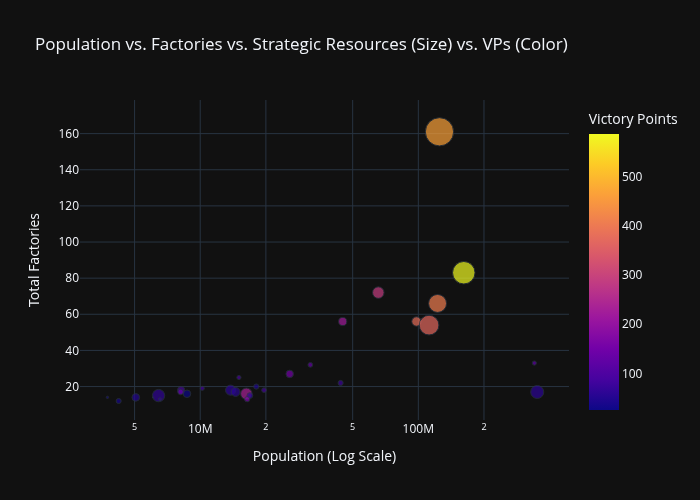

In [14]:
query = """
SELECT 
    c.country_name,
    c.country_tag,
    COUNT(s.state_id) AS total_states,
    SUM(s.population) AS total_population,
    SUM(s.victory_points) AS total_vps,
    SUM(s.civilian_factories) AS total_civs,
    SUM(s.military_factories) AS total_mils,
    SUM(s.naval_factories) AS total_navals,
    SUM(s.total_factories) AS total_factories,
    SUM(s.base_oil) AS total_oil,
    SUM(s.base_aluminum) AS total_aluminum,
    SUM(s.base_rubber) AS total_rubber,
    SUM(s.base_tungsten) AS total_tungsten,
    SUM(s.base_steel) AS total_steel,
    SUM(s.base_chromium) AS total_chromium,
    SUM(s.total_base_resources) AS aggregate_resources
FROM fact_state_1_14_5 s
JOIN dim_country c ON s.owner_tag = c.country_tag
GROUP BY c.country_name, c.country_tag
ORDER BY total_factories DESC;
"""

df_country = pd.read_sql(query, engine)\

fig_bubble = px.scatter(
    df_country.head(30),
    x ="total_population",
    y ="total_factories",
    size="aggregate_resources",
    color="total_vps",
    hover_name="country_name",
    log_x=True,
    title="Population vs. Factories vs. Strategic Resources (Size) vs. VPs (Color)",
    labels={
        "total_population": "Population (Log Scale)",
        "total_factories": "Total Factories",
        "total_resources": "Total Resources",
        "total_vps": "Victory Points"
    },
    template="plotly_dark"
)
fig_bubble.show()